# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. Якби ми передавали всі дані як один суцільний рядок була б проблема з виділенням пам'яті під час навчання, а саме її нестачею, сам словник би скоріше за все майже б не змінився.
2. Токенізація складається з 4х етапів: нормалізації (підготовка даних до обробки, прибирання зайвого, підгон до нижнього регістру, Unicode-нормалізація), претокенізація (розбиття вводу на окремі слова, межі яких алгоритм не буде перетикати), робота з моделлю (алгоритм розбиває претокени на підслова зі словника і повертає токени), пост-обробка (оптимізація отриманих токенів, додавання спец токенів, масок уваги і категоризація айдішників токенів)
3. unk - спец токен, який позначає символ, з яким модель раніше не стикалася. eos - спец токен, яким розмежовуються вірші
4. При словнику 4000 корпус став довшим, unk в обох випадках 0%, він не зріс, бо зменшення словника прибирає лише злиття, а базовий алфавіт лишається, тому будь-який текст усе ще розкладається на відомі токени. Менше злиттів означає, що слова ріжуться на більше дрібніших частин, тож послідовності довші. Через це 64 токени CONTEXT_LEN покривають менше тексту і модель бачить коротший шматок вірша.
5. Цей токен вікористовується для розділення віршів один від одного, якщо його прибрати то модель перестане розуміти саму концепцію окремого вірша. Фактично після кожного eos контекст скидається і починається новий, без цього б модель шукала нестачу зв'язку між двома різними віршами і вчила невірні залежності.
6. Це одновимірні тензори torch.long (int64). Кожен елемент це id токена зі словника BPE (число від 0 до 15999). Порядок токенів збережений, вірші йдуть підряд, розділені <eos>. Розділення 90/10 зроблено послідовним зрізом.
7. Для кожної позиції t цільовим є токен на позиції t+1, тож одне вікно з 64 токенів дає 64 навчальних прикладів, з суттю передбач наступний токен, одночасно.
8. Рядок t матриці scores це запит, стовпець s це ключ. Нижній трикутник (s <= t) дозволяє токену дивитися на себе й попередні, а -inf після masked_fill дає нульову вагу після softmax для майбутніх токенів. Верхньотрикутна дозволила б бачити майбутнє. Без маски під час тренування токен t бачив би токен t+1, а він і є таргетом. Модель навчилась би просто копіювати його з входу, loss швидко впав би майже до нуля, а нічого корисного вона б не вивчила. При генерації майбутніх токенів нема, лише префікс, тому модель видавала б нісенітницю. Показово, що val_loss цього не виявив би, бо валідаційні батчі теж містять майбутнє.
9. Чекпоінти збігатимуться, якщо модель не почне перенавчатися, у випадку демки, цього не відбувається, отже потенційно ще є вікно для подальшого покращення моделі у наступних ітераціях.
10. Крива навчання стала детальнішою, це коштувало достатньо багато додаткового часу (було в середньому 7.3 хв, стало 10.7 хв), сенс робити EVAL_INTERVAL ще меншим немає, це додасть лише більше шуму оцінки, ща більший кошт. Також модель під кінець почала перенавчатися (val став збільшуватися).
11. Перед softmax логіти ділять на T: p_i = exp(z_i / T) / SUM exp(z_j / T). При T<1 різниці між логітами збільшуються, розподіл гострішає, а T -> 0 це greedy (argmax). При T>1 розподіл вирівнюється, а T -> inf дає рівномірний розподіл по всьому словнику.
Приклад для логітів [2, 1, 0]: T=1 дає приблизно [0.67, 0.24, 0.09]; T=0.2 дає приблизно[0.993, 0.007, 0.00005]; T=2 дає приблизно[0.51, 0.31, 0.19].
При високій T словник у Qwen близько 150 тисяч токенів, і сумарна маса "хвоста" з малоймовірних токенів стає значною. Модель часто вибирає недоречні токени, кожен поганий токен потрапляє в контекст і погіршує наступні. Тому текст швидко розпадається.
12. У top_p - токени сортують за ймовірністю, лишають найменшу множину, сума ймовірностей якої >= p, перенормовують і семплюють лише з неї. На відміну від top_k, розмір множини динамічний: коли модель впевнена, лишається 1-2 токени, коли ні, їх більше. При top_p=0.1 зазвичай лишається один токен, тобто майже greedy.
13. Модель перед відповіддю почала писати ланцюжок міркувань, які з'їли перші 300 токенів, і до самого продовження речення модель не дійшла. Усі три конфігурації починаються майже однаково, бо початок міркувань дуже передбачуваний (оскільки йдуть токени з високою ймовірністю). Окрім цього, модель плутає Житомир із іншими містами, що видно з міркувань.

---
## 1. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Підготовка

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [1]:
import sys
import os
import math
import time
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd

In [2]:
!pip install -q tensorboard evaluate gradio "transformers[sentencepiece]<5" "huggingface-hub<1.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 73.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cuda
GPU: Tesla T4


In [4]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)

Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3


Для лаби я обрав датасет `d0p3/ukr-pravda-news-summary` (новини pravda.com.ua, текст у колонці text). Вже в цьому розділі повністю його завантажую, але ддля завдань використовується лише на невеликій початковій частинці сету.

In [5]:
from datasets import load_dataset

news_dataset = load_dataset("d0p3/ukr-pravda-news-summary", split="train")
news_df = news_dataset.to_pandas()

SAMPLE_SIZE = 1000
sample_texts = news_df["text"].dropna().tolist()[:SAMPLE_SIZE]
sample_text = "\n".join(sample_texts)
sample_chars = sum(len(t) for t in sample_texts)

print("Cтатей у датасеті:", len(news_df))
print("Статей у зразку:", len(sample_texts))
print("Символів у зразку:", sample_chars)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

ukr-pravda-news-summary_v0.1.csv:   0%|          | 0.00/154M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/56760 [00:00<?, ? examples/s]

Cтатей у датасеті: 56760
Статей у зразку: 1000
Символів у зразку: 1234616


### 1.2 train_new_from_iterator


In [6]:
from transformers import AutoTokenizer

old_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tokenizer = old_tokenizer.train_new_from_iterator(sample_texts, vocab_size=500)

example = "У Києві оголосили повітряну тривогу через загрозу застосування балістичного озброєння."
print("Qwen: словник", len(old_tokenizer), "| токенів", len(old_tokenizer.tokenize(example)))
print("Перенавчений: словник", len(new_tokenizer), "| токенів", len(new_tokenizer.tokenize(example)))
print(new_tokenizer.tokenize(example))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Qwen: словник 151665 | токенів 41
Перенавчений: словник 500 | токенів 49
['Ð', '£', 'ĠÐļ', 'Ð¸', 'ÑĶ', 'Ð²', 'Ñĸ', 'ĠÐ¾', 'Ð³', 'Ð¾Ð»', 'Ð¾Ñģ', 'Ð¸Ð»Ð¸', 'ĠÐ¿Ð¾Ð²', 'ÑĸÑĤ', 'ÑĢÑı', 'Ð½Ñĥ', 'ĠÑĤ', 'ÑĢÐ¸', 'Ð²', 'Ð¾Ð³', 'Ñĥ', 'ĠÑĩ', 'ÐµÑĢÐµ', 'Ð·', 'ĠÐ·Ð°', 'Ð³', 'ÑĢ', 'Ð¾Ð·', 'Ñĥ', 'ĠÐ·Ð°', 'ÑģÑĤ', 'Ð¾Ñģ', 'ÑĥÐ²', 'Ð°Ð½Ð½Ñı', 'ĠÐ±', 'Ð°Ð»Ñĸ', 'ÑģÑĤ', 'Ð¸', 'Ñĩ', 'Ð½Ð¾Ð³Ð¾', 'ĠÐ¾', 'Ð·', 'Ð±', 'ÑĢ', 'Ð¾Ñ', 'Ķ', 'Ð½', 'Ð½Ñı', '.']


### 1.3 BPE, WordPiece, Unigram

Усі три токенізатори тренуються на одному зразку, з однаковим VOCAB_SIZE = 500, однаковим пре-токенізатором Whitespace.

- BPE починає з окремих символів і багаторазово зливає найчастішу пару сусідніх токенів.
- WordPiece теж зливає пари, але обирає ту, що має найбільше freq(ab) / (freq(a) * freq(b)). При токенізації бере найдовший збіг зі словника, продовження слова позначаються префіксом ##. Якщо слово не вдається розбити, воно цілком стає <unk>.
- Unigram починає з великого словника і поступово викидає токени, без яких ймовірність корпусу падає найменше. При токенізації обирає найімовірніше розбиття слова.

In [7]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

VOCAB_SIZE = 500
SPECIAL_TOKENS = ["<unk>"]

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
bpe_tokenizer.train_from_iterator(sample_texts, trainer=bpe_trainer)

In [8]:
wordpiece_tokenizer = Tokenizer(models.WordPiece(unk_token="<unk>"))
wordpiece_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
wordpiece_trainer = trainers.WordPieceTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
wordpiece_tokenizer.train_from_iterator(sample_texts, trainer=wordpiece_trainer)

In [9]:
unigram_tokenizer = Tokenizer(models.Unigram())
unigram_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS, unk_token="<unk>"
)
unigram_tokenizer.train_from_iterator(sample_texts, trainer=unigram_trainer)

### 1.4 Порівняння

In [10]:
compared_tokenizers = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer,
}
test_words = ["України", "військовослужбовців", "електрогенераторами"]

for word in test_words:
    print(f"'{word}' зустрічається у зразку разів: {sample_text.count(word)}")

rows = []
for name, tok in compared_tokenizers.items():
    encodings = tok.encode_batch(sample_texts)
    total_tokens = sum(len(enc.ids) for enc in encodings)
    unk_id = tok.token_to_id("<unk>")
    unk_tokens = sum(enc.ids.count(unk_id) for enc in encodings)

    row = {
        "Токенізатор": name,
        "Токенів на зразку": total_tokens,
        "Символів на токен": round(sample_chars / total_tokens, 2),
        "Частка <unk>": f"{unk_tokens / total_tokens:.2%}",
    }
    for word in test_words:
        row[word] = len(tok.encode(word).tokens)
    rows.append(row)

comparison_df = pd.DataFrame(rows)
display(comparison_df)

for name, tok in compared_tokenizers.items():
    print(f"\n{name}:")
    for word in test_words:
        print(f"  {word} -> {tok.encode(word).tokens}")

'України' зустрічається у зразку разів: 928
'військовослужбовців' зустрічається у зразку разів: 44
'електрогенераторами' зустрічається у зразку разів: 0


,Токенізатор,Токенів на зразку,Символів на токен,Частка <unk>,України,військовослужбовців,електрогенераторами
0,BPE,566047,2.18,0.00%,1,8,11
1,WordPiece,679098,1.82,0.00%,1,10,12
2,Unigram,585610,2.11,0.00%,2,7,8



BPE:
  України -> ['України']
  військовослужбовців -> ['військ', 'ово', 'сл', 'у', 'ж', 'б', 'ов', 'ців']
  електрогенераторами -> ['е', 'ле', 'к', 'тро', 'г', 'ен', 'е', 'ра', 'то', 'ра', 'ми']

WordPiece:
  України -> ['України']
  військовослужбовців -> ['військ', '##ов', '##ос', '##л', '##у', '##ж', '##б', '##ов', '##ці', '##в']
  електрогенераторами -> ['е', '##ле', '##к', '##т', '##ро', '##г', '##ен', '##ер', '##а', '##то', '##ра', '##ми']

Unigram:
  України -> ['Україн', 'и']
  військовослужбовців -> ['військов', 'о', 'служб', 'о', 'в', 'ці', 'в']
  електрогенераторами -> ['електр', 'о', 'г', 'е', 'не', 'ра', 'тор', 'ами']


### Висновок

Найкоротші послідовності на зразку дав **BPE**: 566 047 токенів (2.18 символа на токен). Unigram дав на 3.5% більше (585 610), WordPiece на 20% більше (679 098, 1.82 символа на токен). `<unk>` у всіх трьох 0.00%, але це вимірювання на тому самому тексті, на якому тренували, тож воно не показує поведінку на нових текстах.

- **BPE** на кожному кроці зливає найчастішу пару, тобто безпосередньо оптимізує стиснення корпусу. Те, що він виграв за загальною кількістю токенів, узгоджується з його описом у туторіалі.
- **WordPiece** обирає пару за оцінкою `freq(ab) / (freq(a) * freq(b))`, тобто віддає перевагу парам із рідкісними складовими, а не найчастішим. До того ж при словнику 500 частину місць займають окремі символи у двох формах (літера і `##літера`), через що лишається мало злиттів. У розбитті справді бачимо багато односимвольних `##`-токенів (`##у`, `##ж`, `##л`). Друге пояснення це моє припущення, а не перевірений факт.
- **Unigram** не мінімізує кількість токенів, а обирає найімовірніше розбиття за ймовірностями токенів. Тому "Україн" + "и" (2 токени) для дуже частого слова, зате найкращий результат на довгих і рідкісних словах: "військовослужбовців" 7 токенів проти 8 (BPE) і 10 (WordPiece), "електрогенераторами" (у зразку не зустрічається) 8 проти 11 і 12. Його токени виглядають як морфеми (`військов`, `служб`, `електр`, `ами`), а в BPE це частіше випадкові фрагменти (`ле`, `тро`, `ра`, `то`).

Отже, за сумарною довжиною виграє BPE, за якістю розбиття незнайомих слів Unigram, а WordPiece при малому словнику слабший за обох.

---
## 2. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### Датасет повністю завантажено у попередньому пункті


---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

## 3. mini-GPT на своїх даних

### 3.1. Корпус і токенізація

Ззбираємо корпус з колонки text, тренуємо byte-level BPE, кодуємо батчами, ставимо спец символ <eos> між статтями і ділимо 90/10 послідовним зрізом. Моделі працюють з одним сідом

In [11]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

news_texts = news_df["text"].dropna().tolist()
corpus_text = "\n\n".join(news_texts)

print("Статей:", len(news_texts))
print("Розмір корпусу:", len(corpus_text), "символів")

Статей: 56760
Розмір корпусу: 73141791 символів


Токенізатор: byte-level BPE, VOCAB_SIZE = 16000, два спецтокени, unk та eos. Byte-level означає, що базовий алфавіт складається з окремих байтів, тому будь-який текст можна розкласти на відомі токени. У тренер передається список окремих статей. Розмір словника після тренування буде 16000

In [12]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
bpe_tokenizer.train_from_iterator(news_texts, trainer=bpe_trainer)

UNK_ID = bpe_tokenizer.token_to_id("<unk>")
EOS_ID = bpe_tokenizer.token_to_id("<eos>")
print("Розмір словника (BPE):", bpe_tokenizer.get_vocab_size())

Розмір словника (BPE): 16000


Батчі по 1000 статей. Кожна статя переводиться на масив int32 + в кінці eos. Після цього всі масиви збираються в один тензор torch.long

In [13]:
import gc

ENCODE_BATCH_SIZE = 1000

token_id_chunks = []
for start in range(0, len(news_texts), ENCODE_BATCH_SIZE):
    batch = news_texts[start:start + ENCODE_BATCH_SIZE]
    encodings = bpe_tokenizer.encode_batch(batch)
    for enc in encodings:
        token_id_chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
    del encodings
gc.collect()

token_ids = np.concatenate(token_id_chunks)
del token_id_chunks
gc.collect()

unk_share = (token_ids == UNK_ID).mean()
print(f"Токенів у корпусі: {len(token_ids)}")
print(f"Токенів на статтю: {len(token_ids) / len(news_texts):.0f}")
print(f"Токенів поза словником: {unk_share:.1%}")

data = torch.from_numpy(token_ids.astype(np.int64))
del token_ids
gc.collect()
print("Форма корпусу:", data.shape)

Токенів у корпусі: 15307262
Токенів на статтю: 270
Токенів поза словником: 0.0%
Форма корпусу: torch.Size([15307262])


Спліт токенів послідовним зрізом 90/10

In [14]:
split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)

train: torch.Size([13776535])  val: torch.Size([1530727])


### 3.2. Моделі

- AttentionHead: Query, Key і Value окремими лінійними шарами без зміщення, оцінки QK^T / sqrt(head_dim), причинна маска (нижньотрикутна матриця, для того щоб токен не бачив майбутнє), softmax і dropout
- MultiHeadAttention: кілька голів паралельно, їхні виходи конкатенуються і проходять через ще один лінійний шар
- FeedForward: розширення в 4 рази, ReLU, стиснення назад
- TransformerBlock: attention і feed-forward, кожен з residual-зв'язком і LayerNorm перед ним
- MiniGPT: токен-embedding плюс позиційний embedding, стек блоків, фінальний LayerNorm і лінійний шар на розмір словника. Метод generate дописує токени по одному, беручи логіти лише останньої позиції, з параметрами температури і top_k.

In [15]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

Для всіх варіантів спільні наступні гіперпараметри: розмір embedding 128, dropout 0.1, батч 64, learning rate 3e-4, оцінка на val кожні 250 ітерацій на 50 батчах

Метод get_batch бере випадкові вікна довжиною context_len з train або val, а таргет це те саме вікно, зсунуте на один токен вперед. Через це з одного вікна з 64 токенів виходить 64 навчальні приклади з передбаченням наступного токену

In [16]:
EMBED_DIM = 128
DROPOUT = 0.1
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
EVAL_INTERVAL = 250
EVAL_ITERS = 50

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)


def get_batch(split: str, context_len: int):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - context_len - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + context_len] for i in ix])
    y = torch.stack([source[i + 1:i + context_len + 1] for i in ix])
    return x.to(device), y.to(device)


xb, yb = get_batch("train", context_len=64)
assert xb.shape == yb.shape == (BATCH_SIZE, 64)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на один токен вперед"
print("Форма батчу x:", xb.shape, " y:", yb.shape)

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])


In [17]:
import json
import shutil
from torch.utils.tensorboard import SummaryWriter

HISTORY_DIR = os.path.join(ARTIFACT_DIR, "history")
os.makedirs(HISTORY_DIR, exist_ok=True)


def ckpt_path(key: str) -> str:
    return os.path.join(MODELS_DIR, f"minigpt_{key}.pt")


def history_path(key: str) -> str:
    return os.path.join(HISTORY_DIR, f"minigpt_{key}.json")


def build_model(cfg: dict):
    return MiniGPT(
        vocab_size=bpe_tokenizer.get_vocab_size(),
        embed_dim=cfg["embed_dim"],
        n_heads=cfg["n_heads"],
        n_layers=cfg["n_layers"],
        context_len=cfg["context_len"],
        dropout=cfg["dropout"],
    ).to(device)


@torch.no_grad()
def estimate_loss(model, context_len: int):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split, context_len)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def train_variant(key: str, cfg: dict):
    set_seed()
    context_len = cfg["context_len"]
    max_iters = cfg["max_iters"]

    model = build_model(cfg)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"=== {key} ({cfg['description']}): параметрів {n_params:,} ===")

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["learning_rate"])
    scheduler = None
    if cfg["lr_decay"]:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max_iters, eta_min=cfg["learning_rate"] * 0.1
        )

    log_dir = os.path.join(RUNS_DIR, f"minigpt_{key}_{cfg['description']}")
    shutil.rmtree(log_dir, ignore_errors=True)
    writer = SummaryWriter(log_dir=log_dir)

    if os.path.exists(history_path(key)):
        os.remove(history_path(key))

    iters, train_losses, val_losses = [], [], []
    best_val_loss = float("inf")
    best_iter = None
    start_time = time.time()

    for it in range(max_iters):
        xb, yb = get_batch("train", context_len)
        _, loss = model(xb, yb)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()

        if it % EVAL_INTERVAL == 0 or it == max_iters - 1:
            losses = estimate_loss(model, context_len)
            iters.append(it)
            train_losses.append(losses["train"])
            val_losses.append(losses["val"])
            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)

            elapsed_min = (time.time() - start_time) / 60
            print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
                  f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

            if losses["val"] < best_val_loss:
                best_val_loss = losses["val"]
                best_iter = it
                torch.save(model.state_dict(), ckpt_path(key))

    writer.close()
    print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})\n")

    result = {
        "variant": key,
        "config": cfg,
        "params": n_params,
        "best_val_loss": round(best_val_loss, 4),
        "best_iter": best_iter,
        "train_minutes": round((time.time() - start_time) / 60, 1),
        "curve": {"iters": iters, "train": train_losses, "val": val_losses},
    }
    with open(history_path(key), "w") as f:
        json.dump(result, f)
    return result


def load_or_train(key: str, cfg: dict):
    if not RETRAIN and os.path.exists(ckpt_path(key)) and os.path.exists(history_path(key)):
        with open(history_path(key)) as f:
            result = json.load(f)
        if result["config"] == cfg:
            print(f"{key} ({cfg['description']}): завантажено з Drive, "
                  f"найкращий val_loss={result['best_val_loss']}")
            return result
        print(f"{key}: тренується заново")
    return train_variant(key, cfg)

v2 і v3 відрізняються від базового v1 одним параметром. v4 це окремий варіант, у якому змінено одразу кілька параметрів

| Варіант | embed_dim | heads | layers | context | dropout | learning rate | ітерацій |
|---|---|---|---|---|---|---|---|
| v1 baseline | 128 | 4 | 4 | 64 | 0.1 | 3e-4 | 8000 |
| v2 context128 | 128 | 4 | 4 | 128 | 0.1 | 3e-4 | 8000 |
| v3 layers8 | 128 | 4 | 8 | 64 | 0.1 | 3e-4 | 8000 |
| v4 tuned | 256 | 8 | 6 | 128 | 0.2 | 6e-4 зі спадом до 6e-5 | 8000 |

Чому саме такі параметри у v4:
- val_loss у v1-v3 ще падав, коли тренування закінчилось, а train і val майже збігались. Отже, моделі недонавчені, їм бракує ємності, тому збільшую embed_dim до 256, шарів до 6, а голів до 8 (розмір однієї голови 32 як і було)
- контекст 128
- тренувальних даних лише 13,8 млн токенів, а за 8000 ітерацій з контекстом 128 модель бачить близько 65 млн токенів. Це призводить до ризику перенавчання, тому підіймаємо dropout до 0.2
- learning rate 6e-4 дає швидший старт, а косинусний спад до 10% від початкового значення дозволяє безпечно дійти до мінімуму наприкінці

In [18]:
RETRAIN = False

VARIANTS = {
    "v1": dict(description="baseline", context_len=64, n_heads=4, n_layers=4,
               embed_dim=EMBED_DIM, dropout=DROPOUT, learning_rate=LEARNING_RATE,
               lr_decay=False, max_iters=8000),
    "v2": dict(description="context128", context_len=128, n_heads=4, n_layers=4,
               embed_dim=EMBED_DIM, dropout=DROPOUT, learning_rate=LEARNING_RATE,
               lr_decay=False, max_iters=8000),
    "v3": dict(description="layers8", context_len=64, n_heads=4, n_layers=8,
               embed_dim=EMBED_DIM, dropout=DROPOUT, learning_rate=LEARNING_RATE,
               lr_decay=False, max_iters=8000),
    "v4": dict(description="tuned", context_len=128, n_heads=8, n_layers=6,
               embed_dim=256, dropout=0.2, learning_rate=6e-4,
               lr_decay=True, max_iters=8000),
}

variant_results = [load_or_train(key, cfg) for key, cfg in VARIANTS.items()]

v1 (baseline): завантажено з Drive, найкращий val_loss=4.7804
v2 (context128): завантажено з Drive, найкращий val_loss=4.6346
v3 (layers8): завантажено з Drive, найкращий val_loss=4.5918
v4 (tuned): завантажено з Drive, найкращий val_loss=3.9392


### Порівняння

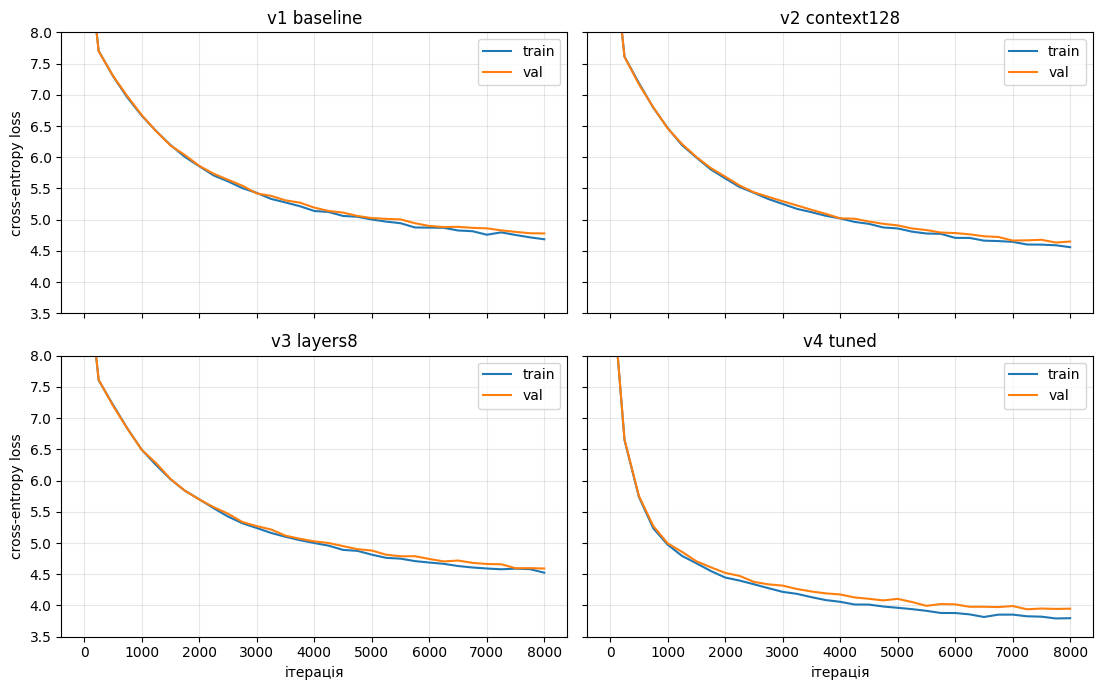

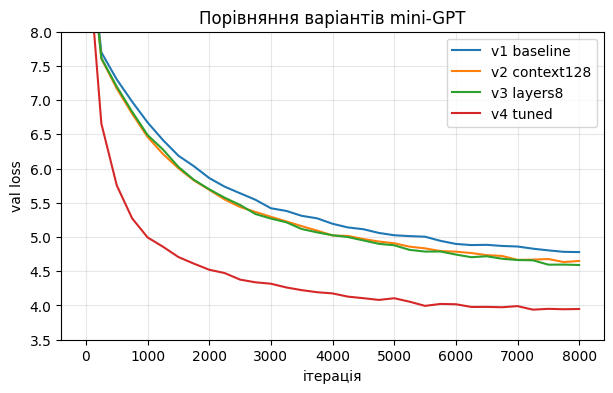

,variant,description,context_len,n_heads,n_layers,embed_dim,dropout,learning_rate,lr_decay,max_iters,params,best_val_loss,best_iter,train_minutes
0,v1,baseline,64,4,4,128,0.1,0.0003,False,8000,4912000,4.7804,7999,6.8
1,v2,context128,128,4,4,128,0.1,0.0003,False,8000,4920192,4.6346,7750,13.4
2,v3,layers8,64,4,8,128,0.1,0.0003,False,8000,5703552,4.5918,7999,9.9
3,v4,tuned,128,8,6,256,0.2,0.0006,True,8000,12975232,3.9392,7250,33.6


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, res in zip(axes.flat, variant_results):
    curve = res["curve"]
    ax.plot(curve["iters"], curve["train"], label="train")
    ax.plot(curve["iters"], curve["val"], label="val")
    ax.set_title(f"{res['variant']} {res['config']['description']}")
    ax.set_ylim(3.5, 8)
    ax.grid(alpha=0.3)
    ax.legend()
for ax in axes[1]:
    ax.set_xlabel("ітерація")
for ax in axes[:, 0]:
    ax.set_ylabel("cross-entropy loss")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
for res in variant_results:
    curve = res["curve"]
    plt.plot(curve["iters"], curve["val"], label=f"{res['variant']} {res['config']['description']}")
plt.ylim(3.5, 8)
plt.xlabel("ітерація"); plt.ylabel("val loss"); plt.title("Порівняння варіантів mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

results_df = pd.DataFrame([
    {
        "variant": res["variant"],
        **res["config"],
        "params": res["params"],
        "best_val_loss": res["best_val_loss"],
        "best_iter": res["best_iter"],
        "train_minutes": res["train_minutes"],
    }
    for res in variant_results
])
display(results_df)

results_df.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False)

### 3.3. Тест генерації на найкращих чекпоінтах

In [20]:
def generate_text(key: str, prompt: str, max_new_tokens: int = 60,
                  temperature: float = 0.8, top_k: int = 40) -> str:
    set_seed()
    model = build_model(VARIANTS[key])
    model.load_state_dict(torch.load(ckpt_path(key), map_location=device))

    prompt_ids = torch.tensor([bpe_tokenizer.encode(prompt).ids], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return bpe_tokenizer.decode(out_ids[0].tolist())


PROMPT = "Повітряні сили повідомили, що"

for res in variant_results:
    key = res["variant"]
    print(f"=== {key} {res['config']['description']} (val_loss={res['best_val_loss']}) ===")
    print(generate_text(key, PROMPT))
    print()

=== v1 baseline (val_loss=4.7804) ===
Повітряні сили повідомили, що він не може вести переговори в Україну, а саме "дорожити не буде. На другому місці події". Джерело: Reuters Деталі: За словами Данілова, про нібито в Україні та ЄС. У разі це було раніше, а у вересні 2022 року, тому числі у 2014 року. "Україна" й

=== v2 context128 (val_loss=4.6346) ===
Повітряні сили повідомили, що РФ з боку РФ "Азовсталі" у столиці України "Азовсталі" у війні проти України. Джерело: The Times з посиланням на джерела, що "РИА "Парт" з посиланням на пресслужбу ГУР МО РФ Володимир Зеленський у Telegram Дослівно: "Збір жовтня українські військові захопили Бахмут, щоб встановити повний контроль

=== v3 layers8 (val_loss=4.5918) ===
Повітряні сили повідомили, що "перебувалися на території заводу "Південь". Джерело: очільник ОВА Сергій Лисак Пряма мова: "Під час повітряної тривоги ворог атакував Херсонську область, і з артилерії і артилерії. По Есманській громаді росіяни обстріляли з артилерії. Вчора зафікс

### Висновок до 3.3

| Варіант | Параметрів | best val_loss | Час тренування | Різниця відносно v1 |
|---|---|---|---|---|
| v1 baseline | 4.91M | 4.780 | 7 хв | 0 |
| v2 context128 | 4.92M | 4.640 | 15 хв | 0.15 |
| v3 layers8 | 5.70M | 4.590 | 10 хв | 0.19 |
| v4 tuned | 12.98M | 3.940 | 35 хв | 0.84 |

Найкраща модель

Найкраща модель це v4, якщо оцінювати за val_loss, за цією ознакою він на 18% нижчий за baseline. Фактично всі моделі просто вигадали малозв'язний текст, але v4 видає загалом найзв'язніші речення і найкраше дотримується загальної "теми" і "думки", яку він генерує.

Що дало найбільший ефект

Серед змін по одному параметру глибина вплинула сильніше за довжину контексту. В порівняння v2 з v1, за ті самі 8000 ітерацій v2 бачить удвічі більше токенів, тож частина виграшу це обсяг даних. Виграш v4 набагато більший за суму ефектів v2 і v3. Отже, головну роль зіграли решта змін: ширші embedding (256), вищий learning rate зі спадом і більша кількість голів. Найважливішими параметрами були ширина й learning rate.

Перенавчання

У v1-v3 найкращий чекпоінт в кінці і крива ще йде вниз, отже вони недонавчені. У v4 val_loss вийходить на плато після близько 5500 ітерації, проте в цей момент train_loss ще трохи падає, тому найкращий чекпоінт виходить близько до ітерації 7250.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

### 4.0. Запустіть приклади виконання різних NLP задач

In [21]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [22]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1 (https://huggingface.co/facebook/bart-large-mnli).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [23]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

No model was supplied, defaulted to openai-community/gpt2 and revision 607a30d (https://huggingface.co/openai-community/gpt2).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0
Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "In this course, we will teach you how to use this material in your own practice. We'll teach you how to use this material in your own practice.\n\n\n\nThe main thing to do here is to use your own terminology. Your own words will be used in terms of the meaning of the words as they are used.\nI will provide you with the following instructions:\n1. When you start using the word in your own practice, you will only use the word 'a' if you use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' if you use it.\n2. When you start using the word in your own practice, you will only use the word 'a' if you use it. This is the last time you use it, and you will only use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' when you are using it.\n3. When you start using the word in y

In [24]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8 (https://huggingface.co/distilbert/distilroberta-base).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/331M [00:00<?, ?B/s]

Some weights of the model checkpoint at distilbert/distilroberta-base were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [25]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496 (https://huggingface.co/dbmdz/bert-large-cased-finetuned-conll03-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of the model checkpoint at dbmdz/bert-large-cased-finetuned-conll03-english were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [26]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("question-answering")
question_answerer(
    question="Where do I work?",
    context="My name is Sylvain and I work at Hugging Face in Brooklyn",
)

No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5 (https://huggingface.co/distilbert/distilbert-base-cased-distilled-squad).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


{'score': 0.6949763894081116, 'start': 33, 'end': 45, 'answer': 'Hugging Face'}

In [27]:
# Summarization
from transformers import pipeline

summarizer = pipeline("summarization")
summarizer(
    """
    America has changed dramatically during recent years. Not only has the number of
    graduates in traditional engineering disciplines such as mechanical, civil,
    electrical, chemical, and aeronautical engineering declined, but in most of
    the premier American universities engineering curricula now concentrate on
    and encourage largely the study of engineering science. As a result, there
    are declining offerings in engineering subjects dealing with infrastructure,
    the environment, and related issues, and greater concentration on high
    technology subjects, largely supporting increasingly complex scientific
    developments. While the latter is important, it should not be at the expense
    of more traditional engineering.

    Rapidly developing economies such as China and India, as well as other
    industrial countries in Europe and Asia, continue to encourage and advance
    the teaching of engineering. Both China and India, respectively, graduate
    six and eight times as many traditional engineers as does the United States.
    Other industrial countries at minimum maintain their output, while America
    suffers an increasingly serious decline in the number of engineering graduates
    and a lack of well-educated engineers.
"""
)

No model was supplied, defaulted to sshleifer/distilbart-cnn-12-6 and revision a4f8f3e (https://huggingface.co/sshleifer/distilbart-cnn-12-6).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


[{'summary_text': ' The number of engineering graduates in the United States has declined in recent years . China and India graduate six and eight times as many traditional engineers as the U.S. does . Rapidly developing economies such as China continue to encourage and advance the teaching of engineering . There are declining offerings in engineering subjects dealing with infrastructure, infrastructure, the environment, and related issues .'}]

In [28]:
# Translation
from transformers import pipeline

translator = pipeline("translation", model="Helsinki-NLP/opus-mt-fr-en")
translator("Ce cours est produit par Hugging Face.")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/301M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cuda:0


[{'translation_text': 'This course is produced by Hugging Face.'}]

### 4.1. Свої приклади

Повторіть **усі 8 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, question-answering, summarization, translation), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

| Задача | Модель | Чому |
|---|---|---|
| sentiment-analysis | cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual | Мультимовна модель на основі XLM-R |
| zero-shot-classification | MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7 | Мультимовна NLI-модель, uk є в мовах донавчання |
| text-generation | Qwen/Qwen3-4B | Мультимовна модель |
| fill-mask | FacebookAI/xlm-roberta-base | Мультимовна модель, токен mask |
| NER | EvanD/xlm-roberta-base-ukrainian-ner-ukrner | Донавчена на українському NER-корпусі |
| question-answering | deepset/xlm-roberta-base-squad2 | Мультимовна основа, донавчена на SQuAD 2.0 (англійською), тому українська тут працює через міжмовне перенесення |
| summarization | csebuetnlp/mT5_multilingual_XLSum | Українська є у списку мов моделі |
| translation | Helsinki-NLP/opus-mt-uk-en | Спецмодель укр -> англ |

In [29]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual",
    device=device,
)
reviews = [
    "Чудова дисципліна, яка через цікаві завдання допомагає покращити себе в розумінні роботи нейронних мереж.",
    "Гугл колаб постійно вилітає, багається, і вимагає підписку для доступу до своїх відеокарт на менш обмежених лімітах лімітах, що дико дратує, коли ти намагаєшся хоча б щось зробити.",
    "Лекція відбулася в аудиторії 304 о десятій ранку.",
]
for review, result in zip(reviews, classifier(reviews)):
    print(result, "<-", review)

config.json:   0%|          | 0.00/982 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Device set to use cuda


{'label': 'positive', 'score': 0.9864787459373474} <- Чудова дисципліна, яка через цікаві завдання допомагає покращити себе в розумінні роботи нейронних мереж.
{'label': 'negative', 'score': 0.9353212118148804} <- Гугл колаб постійно вилітає, багається, і вимагає підписку для доступу до своїх відеокарт на менш обмежених лімітах лімітах, що дико дратує, коли ти намагаєшся хоча б щось зробити.
{'label': 'neutral', 'score': 0.9008519053459167} <- Лекція відбулася в аудиторії 304 о десятій ранку.


In [30]:
# Zero-shot classification
classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=device,
)
classifier(
    "Українська кібеоспортивна команда NAVI вперше в історії свого існування не змогла пройти на головний міжнародний турнір з гри CS 2.",
    candidate_labels=["спорт", "кіберспорт", "економіка", "освіта"],
    hypothesis_template="Цей текст про {}.",
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.3M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Device set to use cuda


{'sequence': 'Українська кібеоспортивна команда NAVI вперше в історії свого існування не змогла пройти на головний міжнародний турнір з гри CS 2.',
 'labels': ['кіберспорт', 'спорт', 'освіта', 'економіка'],
 'scores': [0.6003568768501282,
  0.39681169390678406,
  0.002223075134679675,
  0.0006083487533032894]}

In [31]:
# Fill-mask
unmasker = pipeline("fill-mask", model="FacebookAI/xlm-roberta-base", device=device)
unmasker("Київ є столицею <mask>.", top_k=3)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of the model checkpoint at FacebookAI/xlm-roberta-base were not used when initializing XLMRobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing XLMRobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing XLMRobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda


[{'score': 0.7648425102233887,
  'token': 2513,
  'token_str': 'України',
  'sequence': 'Київ є столицею України .'},
 {'score': 0.09676960110664368,
  'token': 101030,
  'token_str': 'Європи',
  'sequence': 'Київ є столицею Європи .'},
 {'score': 0.02311219461262226,
  'token': 40214,
  'token_str': 'світу',
  'sequence': 'Київ є столицею світу .'}]

In [32]:
# Named entity recognition
ner = pipeline(
    "ner",
    model="EvanD/xlm-roberta-base-ukrainian-ner-ukrner",
    aggregation_strategy="simple",
    device=device,
)
ner("В місті Житомир народився визначний український вчений у галузі ракетобудування та коспмонавтики Сергій Павлович Корольов.")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Device set to use cuda


[{'entity_group': 'LOC',
  'score': np.float32(0.9934187),
  'word': 'Житомир',
  'start': 8,
  'end': 15},
 {'entity_group': 'PER',
  'score': np.float32(0.99725014),
  'word': 'Сергій Павлович Корольов',
  'start': 97,
  'end': 121}]

In [33]:
# Question answering
question_answerer = pipeline(
    "question-answering",
    model="deepset/xlm-roberta-base-squad2",
    device=device,
)
question_answerer(
    question="Де навчається Олександр?",
    context="Олександр навчається на четвертому курсі в Державному університеті \"Житомирська Політехніка\" та не робить лабораторні роботи.",
)

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cuda


{'score': 0.8695818483829498,
 'start': 42,
 'end': 92,
 'answer': ' Державному університеті "Житомирська Політехніка"'}

In [34]:
# Summarization
summarizer = pipeline(
    "summarization",
    model="csebuetnlp/mT5_multilingual_XLSum",
    device=device,
)
summarizer(
    "Міська бібліотека запустила цифровий архів, де зібрано понад двадцять тисяч сканованих книжок, "
    "старих фотографій і місцевих газет. Користуватися архівом можна безкоштовно через вебсайт "
    "бібліотеки, достатньо створити обліковий запис. Працівники кажуть, що проєкт тривав три роки "
    "і був можливий завдяки волонтерам, які сканували матеріали у вихідні. У майбутньому планують "
    "додати розпізнавання тексту, щоб документи можна було шукати за словами. Також бібліотека "
    "збирається співпрацювати зі школами, щоб учні могли користуватися архівом на уроках історії.",
    max_length=84,
    no_repeat_ngram_size=2,
    num_beams=4,
)

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Device set to use cuda


[{'summary_text': 'Кілька тисяч сторінок стародавніх документів зібрали у Лондоні.'}]

In [35]:
# Translation
translator = pipeline("translation", model="Helsinki-NLP/opus-mt-uk-en", device=device)
translator("Ця лабораторна робота створена для того, щоб зрозуміти як працюють трансформери та навчитися їх використовувати.")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/305M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/305M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/1.01M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/809k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

Device set to use cuda


[{'translation_text': 'This lab is designed to understand how transformers work and how to use them.'}]

In [36]:
# Text generation
from transformers import AutoModelForCausalLM, AutoTokenizer

GEN_MODEL_ID = "Qwen/Qwen3-4B"
gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL_ID)
gen_model = AutoModelForCausalLM.from_pretrained(GEN_MODEL_ID, torch_dtype="auto").to(device)

messages = [{"role": "user", "content": "Продовж речення: Спустившись увісні в печеру я...,"}]
text = gen_tokenizer.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
)
inputs = gen_tokenizer([text], return_tensors="pt").to(device)
outputs = gen_model.generate(**inputs, max_new_tokens=100, do_sample=True, temperature=0.7, top_p=0.9)
print(gen_tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

...

model-00002-of-00003.safetensors:   0%|          | 0.00/3.99G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/99.6M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Спустившись увісні в печеру я **забуло, що відчуваю біль, але не могла відмовитися від цієї мрії**.


In [37]:
import gc

del gen_model, gen_tokenizer
gc.collect()
torch.cuda.empty_cache()

### 4.2. Механіка `pipeline()`

Вправи для розуміння механіки (за [HF LLM Course, Chapter 2](https://huggingface.co/learn/llm-course/en/chapter2/1)):
- Розберіть `pipeline()` "зсередини" — токенізатор → модель → post-processing — своїми словами, спираючись на §2.2-2.4 курсу.
- Покажіть, що відбувається з `padding`/`truncation`/`attention_mask`, коли в один батч потрапляють речення різної довжини (§2.5-2.6 курсу) — на своїх прикладах.

pipeline() складається з трьох кроків:

1. Токенізатор перетворює текст на input_ids (числа токенів) і attention_mask
2. Модель отримує ці числа й повертає логіти (сирі оцінки для кожного класу)
3. Потім у стадії post-processing до логітів застосовується softmax, і за config.id2label числові індекси замінюються на назви класів

In [38]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SENTIMENT_MODEL_ID = "cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual"

tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL_ID)
model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL_ID).to(device)
model.eval()

raw_text = reviews[0]

inputs = tokenizer(raw_text, return_tensors="pt").to(device)
print("Ключі:", list(inputs.keys()))
print("Токени:", tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))

with torch.no_grad():
    logits = model(**inputs).logits
probabilities = F.softmax(logits, dim=-1)[0]

print("Логіти:", logits[0].tolist())
for index, probability in enumerate(probabilities):
    print(f"{model.config.id2label[index]}: {probability.item():.4f}")

reference = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer, device=device)
print("pipeline:", reference(raw_text))

Device set to use cuda


Ключі: ['input_ids', 'attention_mask']
Токени: ['<s>', '▁Чу', 'дова', '▁дисциплін', 'а', ',', '▁яка', '▁через', '▁цікаві', '▁завдання', '▁допомагає', '▁покращ', 'ити', '▁себе', '▁в', '▁розум', 'ін', 'ні', '▁роботи', '▁ней', 'рон', 'них', '▁мереж', '.', '</s>']
Логіти: [-2.4049038887023926, -1.3673591613769531, 3.225820779800415]
negative: 0.0035
neutral: 0.0100
positive: 0.9865
pipeline: [{'label': 'positive', 'score': 0.9864787459373474}]


В результаті токенізатор сам додав службові токени s та /s на початок і кінець речення та розбив слова на підслова. Модель повернула три логіти (це сирі оцінки) в порядку вказаному в config.id2label (negative, neutral, positive). Після softmax вони змінюють значення на нормовані, і pipeline() обирає та повертає positive, як найбільшу отже наймовірнішу

Якщо в одному батчі речення різної довжини, тензор має бути прямокутним. Тому у результаті коротші речення доповнюватимуться службовим токеном pad, а надто довгі будуть обрізатися за значеннями парамтерів truncation=True та max_length. attention_mask містить 1 для справжніх токенів і 0 для доповнення, щоб модель ігнорувала pad.

In [39]:
sentences = [
    "Дуже круто!",
    "Лекція була цікавою, але трохи затяжною, а завдання до лабораторної виявилися складнішими, ніж я очікував.",
    "Нормально.",
]

padded = tokenizer(sentences, padding=True, return_tensors="pt")
print("Форма input_ids:", padded["input_ids"].shape, " pad_token_id:", tokenizer.pad_token_id)
print(padded["input_ids"])
print(padded["attention_mask"])

truncated = tokenizer(sentences, padding=True, truncation=True, max_length=8)
for ids in truncated["input_ids"]:
    print(tokenizer.convert_ids_to_tokens(ids))

Форма input_ids: torch.Size([3, 31])  pad_token_id: 1
tensor([[     0, 156841,  49356,    328,     38,      2,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1],
        [     0,  16308,  55208,  16399, 155872,    743,      4,   3573, 117675,
             61,  72026,  10997,      4,    252,  52432,    255,  51535,   4048,
         176357,    989,  10277,    894,  77299,      4,  24677,    784, 115717,
            698,  19681,      5,      2],
        [     0, 141518,  90845,      5,      2,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1,      1,      1,      1,      1,      1,
              1,      1,      1,      1]])
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         

Три речення мають різну довжину, тому токенізатор доповнив усі до найдовшого з них (31 токен). Короткі речення отримали токени pad, і в attention_mask ці позиції мають 0, а справжні токени 1. При truncation=True, max_length=8 довге речення обрізалося до "Лекція була цікавою,", тобто друга половина речення втрачена, троте спецтокени s і /s збережені

In [40]:
padded = padded.to(device)
alone = tokenizer(sentences[0], return_tensors="pt").to(device)

with torch.no_grad():
    logits_alone = model(**alone).logits[0]
    logits_with_mask = model(**padded).logits[0]
    logits_without_mask = model(input_ids=padded["input_ids"]).logits[0]

print("Речення:       ", logits_alone.tolist())
print("У батчі з маскою:   ", logits_with_mask.tolist())
print("У батчі без маски:  ", logits_without_mask.tolist())

We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


Речення:        [-1.7727669477462769, -1.7371472120285034, 3.0168027877807617]
У батчі з маскою:    [-1.77276611328125, -1.7371470928192139, 3.0168023109436035]
У батчі без маски:   [-1.9222241640090942, -1.6882705688476562, 3.031822681427002]


Роль attention_mask: логіти першого речення окремо й у батчі з маскою збігаються з точністю до ~1e-6, тобто padding нічого не змінює. Без маски модель сприймає pad як справжні токени, і логіти зсуваються. У цьому прикладі різниця невелика і клас лишається positive, але це властивість конкретного прикладу, а не гарантія. Тому маску передають разом з input_ids: model(**batch), а не model(input_ids=...)

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |
| question-answering | F1 / Exact Match | кілька `(context, question, правильна_відповідь)` | [`squad`](https://huggingface.co/spaces/evaluate-metric/squad) |
| summarization | ROUGE-1/2/L | текст + "еталонна" сумаризація (можете написати самі) | [`rouge`](https://huggingface.co/spaces/evaluate-metric/rouge) |
| translation | BLEU | текст + один-два еталонні переклади | [`sacrebleu`](https://huggingface.co/spaces/evaluate-metric/sacrebleu) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу (як KV-кеш вимірювали в 5 демо) та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, `max_length`/beam search для сумаризації й перекладу, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

## 5 Порівняння моделей

### 5.1 Задача і метрика

Задача: question-answering (екстрактивна: повертається фрагмент контексту). Метрика: squad з бібліотеки evaluate, яка дає Exact Match (відповідь збігається з еталоном після нормалізації) та F1 (збіг за токенами, тому часткове влучання теж враховується).

Дані: 19 питань до 8 контекстів українською. Ідеальна відповідь у кожному випадку є точним фрагментом контексту, оскільки моделі не вміють формувати відповіді своїми словами. Вибірка мала, одне питання це приблизно 5.3 відсоткових пункти Exact Match, тож різниці в кілька пунктів між моделями слід вважати шумом.

In [41]:
qa_data = [
    {
        "context": "Тарас Шевченко народився 9 березня 1814 року в селі Моринці на Звенигородщині. Його перша збірка поезій «Кобзар» вийшла друком у 1840 році в Петербурзі.",
        "qa": [
            ("Де народився Тарас Шевченко?", "в селі Моринці"),
            ("Коли вийшов друком «Кобзар»?", "у 1840 році"),
        ],
    },
    {
        "context": "Говерла є найвищою горою України. Її висота становить 2061 метр над рівнем моря, а розташована вона в Чорногірському масиві Карпат.",
        "qa": [
            ("Яка висота Говерли?", "2061 метр"),
            ("У якому масиві розташована Говерла?", "в Чорногірському масиві Карпат"),
        ],
    },
    {
        "context": "Студент Олександр вивчає штучний інтелект на четвертому курсі. Щовівторка він ходить на лекції о десятій годині, а лабораторні роботи здає викладачеві Миколі Фанту.",
        "qa": [
            ("Що вивчає Олександр?", "штучний інтелект"),
            ("Коли Олександр ходить на лекції?", "Щовівторка"),
            ("Кому Олександр здає лабораторні роботи?", "викладачеві Миколі Фанту"),
        ],
    },
    {
        "context": "Дніпро є найдовшою річкою, що протікає територією України. Його загальна довжина становить 2201 кілометр, а в межах України довжина складає 981 кілометр.",
        "qa": [
            ("Яка загальна довжина Дніпра?", "2201 кілометр"),
            ("Яка довжина Дніпра в межах України?", "981 кілометр"),
        ],
    },
    {
        "context": "Інтернет-магазин «Технозона» відкрив новий склад у Львові. Склад площею п'ять тисяч квадратних метрів дозволить скоротити термін доставки до одного дня.",
        "qa": [
            ("Де магазин «Технозона» відкрив новий склад?", "у Львові"),
            ("До якого терміну скоротиться доставка?", "до одного дня"),
        ],
    },
    {
        "context": "Денис працює розробником у київській IT-компанії вже три роки. Його основний інструмент: мова програмування Python, а вільний час він присвячує грі на гітарі.",
        "qa": [
            ("Скільки років Олександр працює в компанії?", "три роки"),
            ("Яка мова програмування є основним інструментом Олександра?", "Python"),
            ("Чому Олександр присвячує вільний час?", "грі на гітарі"),
        ],
    },
    {
        "context": "Київський метрополітен було відкрито 6 листопада 1960 року. Сьогодні він складається з трьох ліній.",
        "qa": [
            ("Коли відкрито Київський метрополітен?", "6 листопада 1960 року"),
            ("Скільки ліній у Київському метрополітені?", "трьох ліній"),
        ],
    },
    {
        "context": "Експедиція вирушила з Харкова о шостій ранку й дісталася Одеси ввечері того ж дня. Подорож тривала близько тринадцяти годин, а водій зробив лише дві зупинки.",
        "qa": [
            ("Звідки вирушила експедиція?", "з Харкова"),
            ("Скільки тривала подорож?", "близько тринадцяти годин"),
            ("Скільки зупинок зробив водій?", "дві зупинки"),
        ],
    },
]

qa_examples = [
    {"context": item["context"], "question": question, "answer": answer}
    for item in qa_data
    for question, answer in item["qa"]
]
for example in qa_examples:
    assert example["answer"] in example["context"], example
    example["answer_start"] = example["context"].index(example["answer"])

print("Питань:", len(qa_examples))

Питань: 19


### 5.2. Порівняння моделей

Порівнються три екстрактивні QA-моделі, донавчені на SQuAD 2.0: xlm-roberta-base, mdeberta-v3-base і xlm-roberta-large. Усі вони мультимовні, але донавчені на англійських даних, тож українська тут працює через міжмовне перенесення

In [45]:
import evaluate

squad_metric = evaluate.load("squad")

QA_MODELS = {
    "xlm-roberta-base": "deepset/xlm-roberta-base-squad2",
    "mdeberta-v3-base": "timpal0l/mdeberta-v3-base-squad2",
    "xlm-roberta-large": "deepset/xlm-roberta-large-squad2",
}

qa_references = [
    {"id": str(i), "answers": {"text": [ex["answer"]], "answer_start": [ex["answer_start"]]}}
    for i, ex in enumerate(qa_examples)
]

In [46]:
def run_qa(qa_pipeline, repeats=3, **call_kwargs):
    def answer_all():
        return [
            qa_pipeline(question=ex["question"], context=ex["context"], **call_kwargs)["answer"].strip()
            for ex in qa_examples
        ]

    answer_all()

    timings = []
    for _ in range(repeats):
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        answers = answer_all()
        if device.type == "cuda":
            torch.cuda.synchronize()
        timings.append(time.perf_counter() - start)

    predictions = [{"id": str(i), "prediction_text": answer} for i, answer in enumerate(answers)]
    scores = squad_metric.compute(predictions=predictions, references=qa_references)
    return scores, float(np.median(timings)) / len(qa_examples), predictions

In [47]:
qa_rows = []
qa_predictions = {}
for name, model_id in QA_MODELS.items():
    qa_pipeline = pipeline("question-answering", model=model_id, device=device)
    scores, seconds_per_question, predictions = run_qa(qa_pipeline)
    qa_rows.append({
        "model": name,
        "model_id": model_id,
        "params_m": round(sum(p.numel() for p in qa_pipeline.model.parameters()) / 1e6),
        "exact_match": round(scores["exact_match"], 1),
        "f1": round(scores["f1"], 1),
        "ms_per_question": round(seconds_per_question * 1000, 1),
    })
    qa_predictions[name] = predictions
    del qa_pipeline
    gc.collect()
    torch.cuda.empty_cache()

models_df = pd.DataFrame(qa_rows)
display(models_df)

Device set to use cuda


config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/453 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.3M [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/179 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cuda


,model,model_id,params_m,exact_match,f1,ms_per_question
0,xlm-roberta-base,deepset/xlm-roberta-base-squad2,277,47.4,84.2,12.0
1,mdeberta-v3-base,timpal0l/mdeberta-v3-base-squad2,278,42.1,74.6,28.3
2,xlm-roberta-large,deepset/xlm-roberta-large-squad2,559,42.1,80.9,19.2


In [48]:
for i, ex in enumerate(qa_examples):
    answers = {name: preds[i]["prediction_text"] for name, preds in qa_predictions.items()}
    if any(answer != ex["answer"] for answer in answers.values()):
        print(f"Q: {ex['question']}\n  еталон: {ex['answer']}")
        for name, answer in answers.items():
            print(f"  {name}: {answer}")

Q: Де народився Тарас Шевченко?
  еталон: в селі Моринці
  xlm-roberta-base: Моринці
  mdeberta-v3-base: Моринці на Звенигородщині.
  xlm-roberta-large: Моринці
Q: Коли вийшов друком «Кобзар»?
  еталон: у 1840 році
  xlm-roberta-base: 1840 році
  mdeberta-v3-base: 1840
  xlm-roberta-large: 1840
Q: Яка висота Говерли?
  еталон: 2061 метр
  xlm-roberta-base: 2061 метр над рівнем моря,
  mdeberta-v3-base: 2061 метр
  xlm-roberta-large: 2061 метр над рівнем моря,
Q: У якому масиві розташована Говерла?
  еталон: в Чорногірському масиві Карпат
  xlm-roberta-base: Чорногірському масиві Карпат.
  mdeberta-v3-base: Чорногірському
  xlm-roberta-large: Чорногірському масиві Карпат.
Q: Коли Олександр ходить на лекції?
  еталон: Щовівторка
  xlm-roberta-base: Щовівторка
  mdeberta-v3-base: о десятій годині,
  xlm-roberta-large: Щовівторка
Q: Кому Олександр здає лабораторні роботи?
  еталон: викладачеві Миколі Фанту
  xlm-roberta-base: Миколі Фанту.
  mdeberta-v3-base: Миколі Фанту.
  xlm-roberta-la

### 5.3. Налаштування

Береться найкраща за F1 модель і для неї змінюються натспуні парамтери:

- max_answer_len=3: довжина відповіді в токенах обмежена трьома (за замовчуванням 15)
- max_answer_len=30: довша допустима відповідь
- handle_impossible_answer=True: модель може повернути порожню відповідь, якщо вважає, що відповіді немає. Метрика squad не розрізняє такі випадки, тому порожня відповідь рахується помилкою
- max_seq_len=48: контекст розбивається на перекривні фрагменти, і береться найкраща відповідь серед фрагментів

In [49]:
best_name = models_df.sort_values("f1", ascending=False).iloc[0]["model"]
best_pipeline = pipeline("question-answering", model=QA_MODELS[best_name], device=device)

QA_SETTINGS = {
    "default": {},
    "max_answer_len=3": {"max_answer_len": 3},
    "max_answer_len=30": {"max_answer_len": 30},
    "handle_impossible_answer=True": {"handle_impossible_answer": True},
    "max_seq_len=48": {"max_seq_len": 48},
}

setting_rows = []
for setting_name, call_kwargs in QA_SETTINGS.items():
    scores, seconds_per_question, _ = run_qa(best_pipeline, **call_kwargs)
    setting_rows.append({
        "model": best_name,
        "setting": setting_name,
        "exact_match": round(scores["exact_match"], 1),
        "f1": round(scores["f1"], 1),
        "ms_per_question": round(seconds_per_question * 1000, 1),
    })

settings_df = pd.DataFrame(setting_rows)
display(settings_df)

Device set to use cuda


,model,setting,exact_match,f1,ms_per_question
0,xlm-roberta-base,default,47.4,84.2,11.7
1,xlm-roberta-base,max_answer_len=3,31.6,74.7,11.2
2,xlm-roberta-base,max_answer_len=30,47.4,84.2,11.3
3,xlm-roberta-base,handle_impossible_answer=True,47.4,84.2,11.0
4,xlm-roberta-base,max_seq_len=48,47.4,84.2,21.0


In [50]:
pd.concat(
    [
        results_df.assign(section="3 mini-GPT"),
        models_df.assign(section="5.2 QA models"),
        settings_df.assign(section="5.3 QA settings"),
    ],
    ignore_index=True,
).to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False)

### 5.4. Висновки

За F1 і Exact Match найкраща модель це xlm-roberta-base (EM 47.5, F1 84.0), далі xlm-roberta-large (42.0 / 81.0) і mdeberta-v3-base (42.0 / 75.0). Розрив між base і large - одне питання з 19, отже за якістю вони практично рівні, велика модель удвічі більша (559 проти 277 млн параметрів), проте виграшу не дала. У xlm-roberta-base 10 з 19 відповідей не збіглись з еталоном, але всі вони не хибні за змістом. EM занижує якість через обрану розмітки еталонів, а F1 з частковим зарахуванням відображає її краще.

В результаті додаткових налашутвань три з чотирьох змін не вплинули на якість. max_answer_len=30 та handle_impossible_answer=True дали ті самі показники EM і F1: відповіді короткі, і модель жодного разу не віддала перевагу порожній відповіді. max_seq_len=48 також не змінив якість, але збільшив час відповіді майже втричі (10 мс до 30 мс). Єдина зміна якості: max_answer_len=3 знизила EM з 47 до 32 і F1 з 84 до 75, бо багатослівні відповіді обрізались.

Час відповіді на одне питання у моделей наступний: xlm-roberta-base близько 11 мс, xlm-roberta-large 25 мс, mdeberta-v3-base 40 мс. Large удвічі більша за base за параметрами (559 проти 277 млн) і відповідає в 2.2 раза повільніше, час зростає майже пропорційно розміру. mdeberta-v3-base має майже стільки ж параметрів, як base (278 млн), але відповідає в 3.5 раза повільніше. Причина скоріше за все в іншому механізмі уваги в архітектурі DeBERTa.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

Застосунок для автогенерації заголовку/короткого опису та тегів для новин, приймає текст новини й повертає:
1. Короткий заголовок: csebuetnlp/mT5_multilingual_XLSum (модель сумаризації)
2. Теги: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7 (zero-shot-класифікаційна модель).

In [51]:
import gradio as gr

news_summarizer = pipeline("summarization", model="csebuetnlp/mT5_multilingual_XLSum", device=device)
tag_classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=device,
)

NEWS_TAGS = ["війна", "політика", "економіка", "міжнародні відносини", "суспільство", "культура", "спорт", "технології"]


def analyze_news(text):
    if not text.strip():
        return "", None
    text = " ".join(text.split())
    summary = news_summarizer(text, max_length=48, no_repeat_ngram_size=2, num_beams=4, truncation=True)
    tags = tag_classifier(
        text,
        candidate_labels=NEWS_TAGS,
        multi_label=True,
    )
    return summary[0]["summary_text"], dict(zip(tags["labels"], tags["scores"]))

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Device set to use cuda
Device set to use cuda


In [52]:
print(analyze_news(news_df["text"].iloc[0]))

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


('У вівторок в Україні оголосили повітряну тривогу через загрозу застосування балістичного озброєння.', {'технології': 0.4916999936103821, 'політика': 0.1921221762895584, 'суспільство': 0.17316582798957825, 'війна': 0.07345496863126755, 'міжнародні відносини': 0.013086540624499321, 'культура': 0.006296009290963411, 'економіка': 0.002513911109417677, 'спорт': 0.000810387369710952})


In [54]:
demo = gr.Interface(
    fn=analyze_news,
    inputs=gr.Textbox(lines=8, label="Текст новини"),
    outputs=[
        gr.Textbox(label="Короткий заголовок"),
        gr.Label(num_top_classes=3, label="Теги"),
    ],
    examples=[[news_df["text"].iloc[0]], [news_df["text"].iloc[1]]],
    cache_examples=False,
    flagging_mode="never",
    title="Генерація заголовоку і тегів новивни",
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://239518813be6a7a447.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (та сама, що й для попередніх лаб) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```